# Material de aula - FACENS - Aprendizado de Máquina

Instruções para a realização desta atividade:

1. Faça o download deste notebook Jupyter para sua estação de trabalho
2. Realize as atividades solicitadas dentro do notebook, nos espaços apropriados e indicados
3. Salve o notebook no seguinte padrão: <nome_sobrenome_RA>.ipynb (por exemplo: **rodrigo_caropreso_123456.ipynb ** )
4. Envie o notebook com a atividade realizada na sala de aula da disciplina (Google Classroom)

** DATA DE ENTREGA DESTA ATIVIDADE: 22/12/2018 **

** VALOR DESTA ATIVIDADE: 1,0 ponto **


## <center>ADALINE e Regra Delta - Exercício 01</center>

### Um sistema de gerenciamento automático de controle de duas válvulas, situado a 500 metros de um processo industrial, envia um sinal codificado constituído de quatro grandezas {x1, x2, x3 e x4} que são necessárias para o ajuste de cada uma das válvulas. 

### Conforme mostra a figura abaixo, a mesma via de comunicação é utilizada para acionamento de ambas as válvulas, sendo que o comutador localizado próximo das válvulas deve decidir se o sinal é para a válvula A ou B.

![image.png](attachment:image.png)

### Entretanto, durante a transmissão, os sinais sofrem interferências que alteram o conteúdo das informações transmitidas. Para resolver este problema, a equipe de engenheiros e cientistas pretende treinar uma rede ADALINE para classificar os sinais ruidosos, confirmando ao sistema comutador se os dados devem ser encaminhados para o comando de ajuste da válvula A ou B. 

### Assim, baseado nas medições dos sinais já com ruídos, formou-se um conjunto de treinamento, tomando por convenção o valor –1 para os sinais que devem ser encaminhados para o ajuste da válvula A e o valor +1 se os mesmos devem ser enviados para a válvula B. Assim, a estrutura do ADALINE é mostrada na figura abaixo:


![image.png](attachment:image.png)


### Utilize o algoritmo de treinamento da Regra Delta para classificação de padrões no ADALINE, com os seguintes parâmetros: 

### 1. Taxa de aprendizado $ \eta = 0,0025 $
### 2. Precisão $ \epsilon = 10^{-6} $

Realize as seguintes atividades:

In [1]:
#CÉLULA ADALINE-LIB-01
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [2]:
#CÉLULA ADALINE-LIB-02

#Função para carregamento de dados de treinamento

def loadDataFile(filename) :
    '''
    Esta função faz o carregamento de dados de um arquivo separado por virgulas (csv)
    
    Parametros
    -----------
    filename -> nome do arquivo de dados em formato csv
    
    
    Retorno
    -----------  
    dataframe contendo os dados do arquivo formatados numericamente.
    '''

    dfFile = pd.read_csv(filename, sep=';', decimal=',', thousands='.')
    
    return dfFile

In [3]:
#CÉLULA ADALINE-LIB-03
# Função para cálculo de normalização de uma amostra
def tales(x1, x1_min, x1_max, x2_min, x2_max) :
    #esta função faz o escalamento de 1 amostra x1, que pertence ao intervalo [x1_min, x1_max],
    #dentro do intervalo [x2_min, x2_max]
   
    #Teorema de Tales
    # ( x2 - x2_min ) / ( x2_max - x2_min ) = ( x1 - x1_min ) / (x1_max - % x1_min);
    
    #Definindo x1 como a escala do vetor dado e x2 como a escala de saída (variavel de interesse), isola-se x2:
    x2 = ( ( x1 - x1_min ) / (x1_max - x1_min) )* ( x2_max - x2_min ) + x2_min
    
    return x2

In [4]:
#CÉLULA ADALINE-LIB-04
# Função para cálculo de normalização de um vetor de amostras
def scale(x2_min, x2_max, sampleArray) :
    '''
    Esta função faz o escalamento de 1 vetor de amostras para dentro do intervalo [x2_min, x2_max]
    Ela retorna um vetor com os dados normalizados dentro do dominio dado
    
    Parametros
    -----------
    x2_min      -> valor minimo da escala de destino
    x2_max      -> valor maximo da escala de destino
    sampleArray -> vetor a ser normalizado   
    
    Retorno
    -----------  
    vetor sampleArray projetado dentro do intervalo [x2_min, x2_max]   
    '''
    x_max = max(sampleArray)
    x_min = min(sampleArray)
    
    sampleArrayNorm = [tales(x, x_min, x_max, x2_min, x2_max) for x in sampleArray]
    
    return sampleArrayNorm

In [5]:
#Normalizando array de treino
dfTrainingFile = loadDataFile('Lab01_training.csv')
dfTrainingFile
dfTrainingFileNorm = dfTrainingFile
dfTrainingFileNorm['x1'] = scale(-1,1, dfTrainingFile['x1'])
dfTrainingFileNorm['x2'] = scale(-1,1, dfTrainingFile['x2'])
dfTrainingFileNorm['x3'] = scale(-1,1, dfTrainingFile['x3'])
dfTrainingFileNorm['x4'] = scale(-1,1, dfTrainingFile['x4'])

dfTrainingFile.head()

,Amostra,x1,x2,x3,x4,d
0,1,-0.019839,-0.308281,0.452773,-0.612666,1
1,2,-0.153637,0.286612,0.703611,0.267550,-1
2,3,-0.325370,-0.037913,1.000000,-0.269168,-1
3,4,-0.117753,-0.436292,-0.070119,-0.558274,-1
4,5,0.708617,0.183616,0.392715,-0.102057,1


In [6]:
#Normalizando array de teste
dfTestFile = loadDataFile('Lab01_operation.csv')
dfTestFile
dfTestFileNorm = dfTrainingFile
dfTestFileNorm['x1'] = scale(-1,1, dfTestFileNorm['x1'])
dfTestFileNorm['x2'] = scale(-1,1, dfTestFileNorm['x2'])
dfTestFileNorm['x3'] = scale(-1,1, dfTestFileNorm['x3'])
dfTestFileNorm['x4'] = scale(-1,1, dfTestFileNorm['x4'])

dfTrainingFileNorm.head()

,Amostra,x1,x2,x3,x4,d
0,1,-0.019839,-0.308281,0.452773,-0.612666,1
1,2,-0.153637,0.286612,0.703611,0.267550,-1
2,3,-0.325370,-0.037913,1.000000,-0.269168,-1
3,4,-0.117753,-0.436292,-0.070119,-0.558274,-1
4,5,0.708617,0.183616,0.392715,-0.102057,1


In [7]:
#CÉLULA ADALINE-LIB-05
def adaline_train(eta, epsilon, vInputs, vOutputs, max_epochs) :
    '''
    Algoritmo de treinamento do ADALINE
    
    Parametros
    -----------
    eta        -> taxa de aprendizado
    epsilon    -> criterio de parada baseado em minimo erro quadratico médio
    inputs     -> vetor/matriz com as entradas
    outputs    -> vetor/matriz com as saidas
    max_epochs -> criterio de parada por epocas de treinamento
    
    Retorno
    -------
    Este método retorna uma tupla contendo o vetor de pesos ajustado, o numero de epocas executadas no treinamento e os valores 
    do Erro Quadrático Médio (EQM) em cada época.
    '''
    
    nInputs  = vInputs.shape[0]
    nSamples = vInputs.shape[1]
        
    # nInputs rows x 1 colum
    vWeights = np.random.rand(nInputs, 1)
    
    #criação de uma variável global para ser chamada na execução do adaline
    weights_in = vWeights.copy()
    global w_in
    #convert a matriz em um vetor
    w_in = np.squeeze(np.asarray(weights_in))
    
    MSE = [] #Mean Squared Error
    M = {}
    
    for epochCounter in range(max_epochs) :
        
        epoch_error = 0  #valor de erro 
        correction = False #Flag de parada
        for k in range(nSamples) :
            #Com esta notação, pegaremos a coluna k no formato de vetor-coluna vInputs[:, [k]]
            #Com esta notação, pegaremos a coluna k no formato de vetorlinha vInputs[:, k]
            x = vInputs[:, [k]]
            d = vOutputs[k]
            
            #Calcula saída do bloco associador do ADALINE
            u = np.matmul(vWeights.T, x)

            #Corrige pesos
            vWeights += eta * (d - u) * x

            #Acumula o erro do bloco associador para uma época de treinamento
            epoch_error += (d - u)**2           
        
        
        #Calcula o EQM e verifica criterio de parada
        MSE.append( np.asscalar(epoch_error / nSamples))
        
        if( epochCounter > 0 and abs(MSE[epochCounter] - MSE[epochCounter-1]) < epsilon ) :
            break            
    
    return (vWeights, epochCounter+1, MSE)

In [8]:
#CÉLULA ADALINE-LIB-06

def adaline_operation(vWeights, vInputs) :
    '''Algoritmo de operação do ADALINE Simples
    
    Parametros
    -----------
    vWeights : vetor/matriz com os pesos
    inputs   : vetor/matriz com as entradas
    
    Retorno
    -------
    Este método retorna o valor de saída do ADALINE calculado segundo sua função de ativação signal(.)   
    ''' 

    x = vInputs

    #Calcula saída do ADALINE
    u = np.matmul(vWeights.T, x)
    y = np.sign(u)
    
    return np.asscalar(y) #converte o numpy array 1x1 em um unico valor escalar.

In [9]:
#construção da tabela
table = pd.DataFrame(index=['T1','T2','T3','T4','T5'],columns=['w0 inicial', 'w1 inicial', 'w2 inicial', 'w3 inicial', 'w4 inicial', 'w0 final', 'w1 final', 'w2 final', 'w3 final', 'w4 final', 'Epocas']).reset_index().rename(columns={'index':'T'}).set_index('T')
table

,w0 inicial,w1 inicial,w2 inicial,w3 inicial,w4 inicial,w0 final,w1 final,w2 final,w3 final,w4 final,Epocas
T,,,,,,,,,,,
T1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
T5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## ADALINE - inicio

In [10]:
#CÉLULA ADALINE-MAIN-01
mse_dict = {}
for i in range(1,6):
    if i <= 5:
        #Parâmetros
        eta = 0.0025
        epsilon = 10**(-6)
        nInputs = 4
        max_epochs = 10000

        #Carrega dados - Treino
        dfTrainingFile = loadDataFile('Lab01_training.csv')
        dfTrainingFileNorm = dfTrainingFile
        dfTrainingFileNorm['x1'] = scale(-1,1, dfTrainingFile['x1'])
        dfTrainingFileNorm['x2'] = scale(-1,1, dfTrainingFile['x2'])
        dfTrainingFileNorm['x3'] = scale(-1,1, dfTrainingFile['x3'])
        dfTrainingFileNorm['x4'] = scale(-1,1, dfTrainingFile['x4'])

        nSamples = len (dfTrainingFileNorm['x1'])

        col0 = np.ones((nSamples, 1)) * (-1)
        col1 = dfTrainingFileNorm['x1'].values.reshape(nSamples, 1)
        col2 = dfTrainingFileNorm['x2'].values.reshape(nSamples, 1)
        col3 = dfTrainingFileNorm['x3'].values.reshape(nSamples, 1)
        col4 = dfTrainingFileNorm['x4'].values.reshape(nSamples, 1)

        vInputs = np.array(col0)
        vInputs = np.append(vInputs, col1, axis=1) #axis = 1 -> coluna
        vInputs = np.append(vInputs, col2, axis=1) #axis = 1 -> coluna
        vInputs = np.append(vInputs, col3, axis=1) #axis = 1 -> coluna
        vInputs = np.append(vInputs, col4, axis=1) #axis = 1 -> coluna

        vOutputs = dfTrainingFileNorm['d'].values.reshape(nSamples, 1)

        (vWeights, nEpochs, MSE) = adaline_train(eta, epsilon, vInputs.T, vOutputs, max_epochs)
        
        #guardar os resultados dos MSEs em um dicionário
        mse_dict[i] = MSE
        print('Epoch',i,':',len(MSE))
        
        #convert a matriz em um vetor com os pesos de saída
        w_out = np.squeeze(np.asarray(vWeights))
        #concatena os vetores
        t = np.insert([w_in,w_out],(10),nEpochs)
        #insere os valores na tabela
        table.iloc[i-1,:] = t
        
        i += 1     
table

Epoch 1 : 3237
Epoch 2 : 3167
Epoch 3 : 3141
Epoch 4 : 3196
Epoch 5 : 3183


,w0 inicial,w1 inicial,w2 inicial,w3 inicial,w4 inicial,w0 final,w1 final,w2 final,w3 final,w4 final,Epocas
T,,,,,,,,,,,
T1,0.97068,0.218311,0.17843,0.752154,0.68227,0.643338,1.26192,4.34022,-0.287839,-4.83095,3237
T2,0.0515727,0.815112,0.31155,0.516334,0.0192769,0.643341,1.26192,4.34024,-0.28784,-4.83097,3167
T3,0.510675,0.570231,0.859212,0.545032,0.327105,0.64335,1.26194,4.3403,-0.287841,-4.83103,3141
T4,0.852316,0.703808,0.567142,0.883607,0.676226,0.643353,1.26194,4.34033,-0.287841,-4.83106,3196
T5,0.245299,0.0271746,0.78233,0.517341,0.557784,0.643341,1.26192,4.34024,-0.28784,-4.83097,3183


In [11]:
#Verifica resultados 

y=[]
for k in range(nSamples):
    y.append(adaline_operation(vWeights, vInputs[[k], :].T))

dfValidation = dfTrainingFile.copy()
dfValidation['y'] = y

results = dfValidation['y'] == dfValidation['d']
accuracy = sum(results) / len(results) * 100

print('Taxa de acerto do conjunto de treinamento: {}%'.format(accuracy))

Taxa de acerto do conjunto de treinamento: 91.42857142857143%


In [12]:
#Carrega dados - Teste
table = table.reset_index()

dfTestFile = loadDataFile('Lab01_operation.csv')
dfTestFileNorm = dfTestFile.copy()

dfTestFileNorm['x1'] = scale(-1,1, dfTestFileNorm['x1'])
dfTestFileNorm['x2'] = scale(-1,1, dfTestFileNorm['x2'])
dfTestFileNorm['x3'] = scale(-1,1, dfTestFileNorm['x3'])
dfTestFileNorm['x4'] = scale(-1,1, dfTestFileNorm['x4'])

nSamples = len (dfTestFileNorm['x1'])

col0 = np.ones((nSamples, 1)) * (-1)
col1 = dfTestFileNorm['x1'].values.reshape(nSamples, 1)
col2 = dfTestFileNorm['x2'].values.reshape(nSamples, 1)
col3 = dfTestFileNorm['x3'].values.reshape(nSamples, 1)
col4 = dfTestFileNorm['x4'].values.reshape(nSamples, 1)

vTestInputs = np.array(col0)
vTestInputs = np.append(vTestInputs, col1, axis=1) #axis = 1 -> coluna
vTestInputs = np.append(vTestInputs, col2, axis=1) #axis = 1 -> coluna
vTestInputs = np.append(vTestInputs, col3, axis=1) #axis = 1 -> coluna
vTestInputs = np.append(vTestInputs, col4, axis=1) #axis = 1 -> coluna

for i in range(0,5,1):
    #coleta os valores dos pesos de saída da tabela
    w_outs = table.iloc[i,6:11].values
    vectors = np.asarray(w_outs,dtype=np.float)
    
    y=[]
    for k in range(nSamples):
        y.append(adaline_operation(vectors, vInputs[[k], :].T))
    dfTestFile['y_'+table.iloc[i,0]] = y
dfTestFile

,Amostra,x1,x2,x3,x4,y_T1,y_T2,y_T3,y_T4,y_T5
0,1,0.9694,0.6909,0.4334,3.4965,1.0,1.0,1.0,1.0,1.0
1,2,0.5427,1.3832,0.6390,4.0352,-1.0,-1.0,-1.0,-1.0,-1.0
2,3,0.6081,-0.9196,0.5925,0.1016,-1.0,-1.0,-1.0,-1.0,-1.0
3,4,-0.1618,0.4694,0.2030,3.0117,1.0,1.0,1.0,1.0,1.0
4,5,0.1870,-0.2578,0.6124,1.7749,1.0,1.0,1.0,1.0,1.0
5,6,0.4891,-0.5276,0.4378,0.6439,1.0,1.0,1.0,1.0,1.0
6,7,0.3777,2.0149,0.7423,3.3932,1.0,1.0,1.0,1.0,1.0
7,8,1.1498,-0.4067,0.2469,1.5866,1.0,1.0,1.0,1.0,1.0
8,9,0.9325,1.0950,1.0359,3.3591,-1.0,-1.0,-1.0,-1.0,-1.0
9,10,0.5060,1.3317,0.9222,3.7174,-1.0,-1.0,-1.0,-1.0,-1.0


In [13]:
#Referencia para string format em python: https://docs.python.org/3.4/library/string.html
#print('Entradas: [{: 6.4f}, {: 6.4f}, {: 6.4f}] - Classe = {} ({: })'.format( round(inValue[1], 4), round(inValue[2], 4), round(inValue[3], 4), outClass, outValue))
dfTestFile['y'] = y

classes = [ 'A' if(x==-1) else 'B' for x in y]
dfTestFile['classes'] = classes

#Exibe o dataframe com entradas e saidas classificadas
dfTestFile

,Amostra,x1,x2,x3,x4,y_T1,y_T2,y_T3,y_T4,y_T5,y,classes
0,1,0.9694,0.6909,0.4334,3.4965,1.0,1.0,1.0,1.0,1.0,1.0,B
1,2,0.5427,1.3832,0.6390,4.0352,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A
2,3,0.6081,-0.9196,0.5925,0.1016,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A
3,4,-0.1618,0.4694,0.2030,3.0117,1.0,1.0,1.0,1.0,1.0,1.0,B
4,5,0.1870,-0.2578,0.6124,1.7749,1.0,1.0,1.0,1.0,1.0,1.0,B
5,6,0.4891,-0.5276,0.4378,0.6439,1.0,1.0,1.0,1.0,1.0,1.0,B
6,7,0.3777,2.0149,0.7423,3.3932,1.0,1.0,1.0,1.0,1.0,1.0,B
7,8,1.1498,-0.4067,0.2469,1.5866,1.0,1.0,1.0,1.0,1.0,1.0,B
8,9,0.9325,1.0950,1.0359,3.3591,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A
9,10,0.5060,1.3317,0.9222,3.7174,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A


### Gráfico EQM do primeiro treinamento

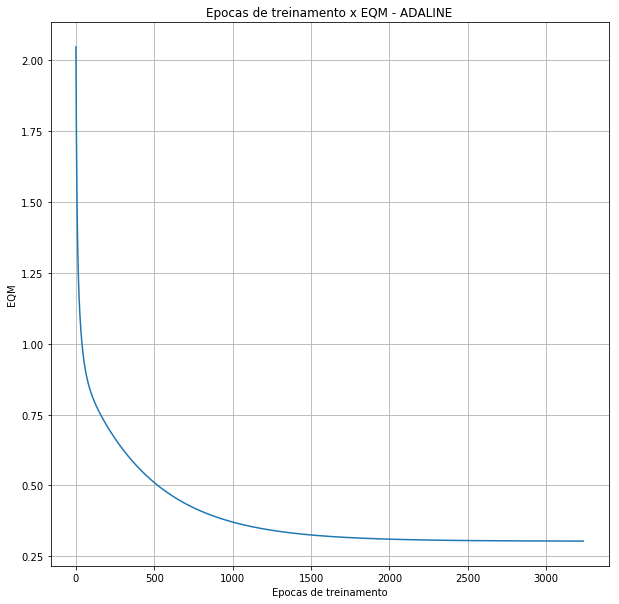

In [14]:
fig = plt.figure(figsize=(10,10))
plt.grid()
plt.xlabel('Epocas de treinamento')
plt.ylabel('EQM')
plt.title('Epocas de treinamento x EQM - ADALINE')
plt.plot(range(len(mse_dict[1])), mse_dict[1])

### Gráfico EQM do segundo treinamento

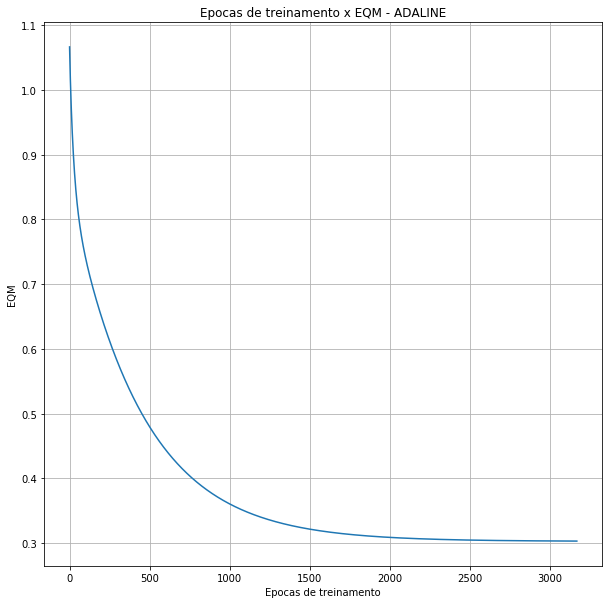

In [15]:
fig = plt.figure(figsize=(10,10))
plt.grid()
plt.xlabel('Epocas de treinamento')
plt.ylabel('EQM')
plt.title('Epocas de treinamento x EQM - ADALINE')
plt.plot(range(len(mse_dict[2])), mse_dict[2])

# <center> Atividades </center>

1 - Execute 5 treinamentos para a rede ADALINE, inicializando-se o vetor de pesos em cada treinamento com valores aleatórios entre zero e um. Se for o caso, reinicie o gerador de números aleatórios em cada treinamento de tal forma que os elementos do vetor de pesos iniciais não sejam os mesmos.

2 - Registre os pesos dos treinamentos na tabela abaixo (fazer tabela);


| T  |    w0    |    w1    |    w2    |    w3    |    w4    |    w0    |    w1    |    w2    |    w3    |    w4    |  Epocas  |
|----|----------|----------|----------|----------|----------|----------|----------|----------|----------|----------|----------|
| T1 |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |   xxxx   |
| T2 |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |   xxxx   |
| T3 |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |   xxxx   |
| T4 |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |   xxxx   |
| T5 |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |  xxxxxx  |   xxxx   |


3 - Para os dois primeiros treinamentos realizados acima, trace então os respectivos gráficos dos valores de erro quadrático médio (EQM) em função de cada época de treinamento.


4 - Para todos os treinamentos realizados, aplique então a rede ADALINE para classificar e indicar ao comutador se os sinais seguintes devem ser encaminhados para a válvula A ou B.

| Amostra  |     x1     |     x2     |     x3     |     x4     |  y_T1  |  y_T2  |  y_T3  |  y_T4  |  y_T5  |
|----------|------------|------------|------------|------------|--------|--------|--------|--------|--------|
|    01    |   0.9694   |   0.6909   |   0.4334   |   3.4965   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    02    |   0.5427   |   1.3832   |   0.6390   |   4.0352   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    03    |   0.6081   |  -0.9196   |   0.5925   |   0.1016   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    04    |  -0.1618   |   0.4694   |   0.2030   |   3.0117   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    05    |   0.1870   |  -0.2578   |   0.6124   |   1.7749   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    06    |   0.4891   |  -0.5276   |   0.4378   |   0.6439   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    07    |   0.3777   |   2.0149   |   0.7423   |   3.3932   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    08    |   1.1498   |  -0.4067   |   0.2469   |   1.5866   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    09    |   0.9325   |   1.0950   |   1.0359   |   3.3591   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    10    |   0.5060   |   1.3317   |   0.9222   |   3.7174   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    11    |   0.0497   |  -2.0656   |   0.6124   |  -0.6585   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    12    |   0.4004   |   3.5369   |   0.9766   |   5.3532   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    13    |  -0.1874   |   1.3343   |   0.5374   |   3.2189   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    14    |   0.5060   |   1.3317   |   0.9222   |   3.7174   |   xx   |   xx   |   xx   |   xx   |   xx   |
|    15    |   1.6375   |  -0.7911   |   0.7537   |   0.5515   |   xx   |   xx   |   xx   |   xx   |   xx   |

5 - Embora o número de épocas de cada treinamento realizado no item 2 seja diferente, explique por que então os valores dos pesos continuam praticamente inalterados.

Resposta 2:

In [16]:
table

,T,w0 inicial,w1 inicial,w2 inicial,w3 inicial,w4 inicial,w0 final,w1 final,w2 final,w3 final,w4 final,Epocas
0,T1,0.97068,0.218311,0.17843,0.752154,0.68227,0.643338,1.26192,4.34022,-0.287839,-4.83095,3237
1,T2,0.0515727,0.815112,0.31155,0.516334,0.0192769,0.643341,1.26192,4.34024,-0.28784,-4.83097,3167
2,T3,0.510675,0.570231,0.859212,0.545032,0.327105,0.64335,1.26194,4.3403,-0.287841,-4.83103,3141
3,T4,0.852316,0.703808,0.567142,0.883607,0.676226,0.643353,1.26194,4.34033,-0.287841,-4.83106,3196
4,T5,0.245299,0.0271746,0.78233,0.517341,0.557784,0.643341,1.26192,4.34024,-0.28784,-4.83097,3183


Resposta 4:

In [17]:
dfTestFile

,Amostra,x1,x2,x3,x4,y_T1,y_T2,y_T3,y_T4,y_T5,y,classes
0,1,0.9694,0.6909,0.4334,3.4965,1.0,1.0,1.0,1.0,1.0,1.0,B
1,2,0.5427,1.3832,0.6390,4.0352,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A
2,3,0.6081,-0.9196,0.5925,0.1016,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A
3,4,-0.1618,0.4694,0.2030,3.0117,1.0,1.0,1.0,1.0,1.0,1.0,B
4,5,0.1870,-0.2578,0.6124,1.7749,1.0,1.0,1.0,1.0,1.0,1.0,B
5,6,0.4891,-0.5276,0.4378,0.6439,1.0,1.0,1.0,1.0,1.0,1.0,B
6,7,0.3777,2.0149,0.7423,3.3932,1.0,1.0,1.0,1.0,1.0,1.0,B
7,8,1.1498,-0.4067,0.2469,1.5866,1.0,1.0,1.0,1.0,1.0,1.0,B
8,9,0.9325,1.0950,1.0359,3.3591,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A
9,10,0.5060,1.3317,0.9222,3.7174,-1.0,-1.0,-1.0,-1.0,-1.0,-1.0,A


Resposta 5:

Porque o adaline demora para chegar a um valor hiperplano ótimo, então após os treinamentos os valores de pesos corrigidos estarão bem próximos e todos usam o mesmo valor de épsilon.